
# Customer Segmentation Analysis

**Name:** Mohini More  
**Organization:** Oasis Infobyte  
**Internship Track:** Data Analytics  
**Task:** Level 1 — Task 2  
**Tools Used:** Python, Pandas, Scikit-learn, Matplotlib, Seaborn, Jupyter Notebook

## Project Objective

The objective of this project is to segment customers based on their purchasing behaviour using RFM (Recency, Frequency, Monetary) analysis and the K-Means clustering algorithm. The results will help identify different customer groups and recommend suitable marketing strategies for each segment.



## 1. Import Libraries and Load the Dataset


In [44]:

# Required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [45]:
# Load the dataset
df = pd.read_csv("C:\OASIS Data Analytics Project\Task_2 online_retail.csv")
df.head()


<>:2: SyntaxWarning: "\O" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\O"? A raw string is also an option.
<>:2: SyntaxWarning: "\O" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\O"? A raw string is also an option.
C:\Users\DELL\AppData\Local\Temp\ipykernel_21544\770205862.py:2: SyntaxWarning: "\O" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\O"? A raw string is also an option.
  df = pd.read_csv("C:\OASIS Data Analytics Project\Task_2 online_retail.csv")


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [46]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names, data types, and non-null counts
df.info()

# Count missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

Dataset shape: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64



## 2. Data Cleaning and Preparation
Before cleaning, we need to check missing values, duplicate rows, and invalid transactions.


In [47]:

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check missing Customer IDs
print("Missing Customer IDs:", df["CustomerID"].isnull().sum())

# Check missing descriptions
print("Missing Descriptions:", df["Description"].isnull().sum())

# Check transaction quantities and prices
print("Zero or negative quantities:", (df["Quantity"] <= 0).sum())
print("Negative or zero unit prices:", (df["UnitPrice"] <= 0).sum())

# Check date column
print("Date data type:", df["InvoiceDate"].dtype)


Duplicate rows: 5268
Missing Customer IDs: 135080
Missing Descriptions: 1454
Zero or negative quantities: 10624
Negative or zero unit prices: 2517
Date data type: str



###  Handling Duplicates, Missing Values, and Invalid Transactions


In [48]:

# Create a cleaned copy while keeping the original dataset unchanged
df_clean = df.copy()

# Convert InvoiceDate from text to datetime
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows without a CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"])

# Remove rows with invalid dates
df_clean = df_clean.dropna(subset=["InvoiceDate"])

# Keep positive quantities and positive unit prices
# This focuses our analysis on valid sales, excluding returns
# and transactions with zero or negative prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Display the cleaning results
print("Original dataset rows:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Remaining missing CustomerIDs:", df_clean["CustomerID"].isnull().sum())
print("Remaining duplicate rows:", df_clean.duplicated().sum())
print("InvoiceDate data type:", df_clean["InvoiceDate"].dtype)

# Display the first five cleaned rows
df_clean.head()


Original dataset rows: 541909
Rows after cleaning: 392692
Rows removed: 149217
Remaining missing CustomerIDs: 0
Remaining duplicate rows: 0
InvoiceDate data type: datetime64[us]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



## 3. RFM (Recency, Frequency, Monetary) Analysis

RFM analysis measures customer purchasing behaviour using the date of their most recent purchase, the number of purchases made, and total spending. These features will be used to prepare customer-level data for K-Means clustering.

Recency: How many days since a customer last purchased?

Frequency: How many times has the customer purchased?

Monetary: How much money has the customer spent?

In [49]:

# Calculate the total value of each transaction line
df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Updated dataset
df_clean[
    ["InvoiceNo", "CustomerID", "Quantity", "UnitPrice", "TotalAmount"]
].head()


,InvoiceNo,CustomerID,Quantity,UnitPrice,TotalAmount
0,536365,17850.0,6,2.55,15.30
1,536365,17850.0,6,3.39,20.34
2,536365,17850.0,8,2.75,22.00
3,536365,17850.0,6,3.39,20.34
4,536365,17850.0,6,3.39,20.34



## Calculate Customer-Level RFM Values


In [50]:

# Set the reference date to one day after the latest transaction
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM values for each customer
rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
).reset_index()
rfm.head()




,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [51]:

# Display descriptive statistics for customer purchasing behaviour
print("Total customers:", rfm["CustomerID"].nunique())

print("\nRFM Summary Statistics:")
print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))


Total customers: 4338

RFM Summary Statistics:
       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     92.54       4.27    2048.69
std     100.01       7.70    8985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.00       5.00    1660.60
max     374.00     209.00  280206.02


## 4. Preparing Data for Clustering

In [52]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [53]:
from sklearn.preprocessing import StandardScaler

# Select RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]

# Standardise the RFM features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

print("RFM features scaled successfully.")
print(rfm_scaled[:5])

RFM features scaled successfully.
[[ 2.33457414 -0.4250965   8.36301037]
 [-0.90534032  0.3544168   0.2516989 ]
 [-0.17535959 -0.03533985 -0.02798783]
 [-0.73534481 -0.4250965  -0.03240559]
 [ 2.17457836 -0.4250965  -0.19081155]]


## 5. Choosing the Number of Clusters Using the Elbow Method

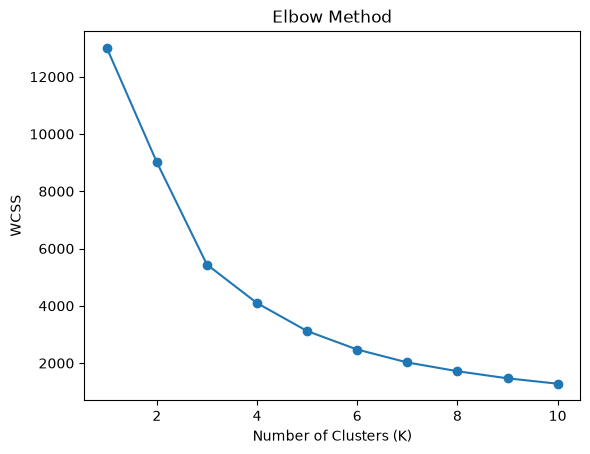

In [54]:
# Import KMeans
from sklearn.cluster import KMeans

# Calculate the WCSS(Within-Cluster Sum of Squares) for different numbers of clusters
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(rfm_scaled)
    wcss.append(model.inertia_)

# Plot the Elbow Method graph
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

### Interpretation of the Elbow Method

The Elbow Method was used to determine a suitable number
of clusters for customer segmentation. The WCSS value
decreases as the number of clusters increases, with a
steep decline at lower values of K and a more gradual
decline at higher values.

The curve suggests that 3 to 4 clusters may be suitable.
For the initial analysis, 3 clusters will be used to
segment customers based on their Recency, Frequency,
and Monetary values.

## 6. Applying K-Means Clustering

In [55]:
# Create 3 customer clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Assigning  each customer to a cluster
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)
rfm.head()


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,0
1,12347.0,2,7,4310.00,1
2,12348.0,75,4,1797.24,1
3,12349.0,19,1,1757.55,1
4,12350.0,310,1,334.40,0


## 7. Customer Segment Profiling

In [56]:
# Calculate average RFM values for each cluster
cluster_profile = rfm.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

cluster_profile

,Recency,Frequency,Monetary
Cluster,,,
0,247.11,1.58,629.66
1,41.45,4.67,1849.67
2,6.04,66.42,85826.08


## 8. Customer Count by Cluster

In [57]:
# Count customers in each cluster
print(rfm["Cluster"].value_counts().sort_index())

Cluster
0    1082
1    3230
2      26
Name: count, dtype: int64


## 9. Visualising Customer Distribution

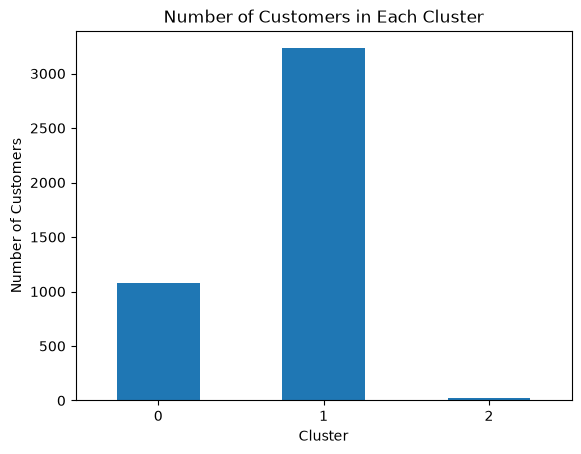

In [58]:
# Plot the number of customers in each cluster
rfm["Cluster"].value_counts().sort_index().plot(kind="bar")

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

### Interpretation

The bar chart shows the distribution of 4,338 customers across three clusters. Cluster 1 contains 3,230 customers (74.5%), making it the largest segment. Cluster 0 contains 1,082 customers (24.9%), while Cluster 2 contains only 26 customers (0.6%).

This distribution indicates that most customers belong to Cluster 1, followed by Cluster 0, while Cluster 2 represents a very small group of high-value customers.


## 10. Visualising Customer Segments


### 10.1 Frequency vs Monetary Value

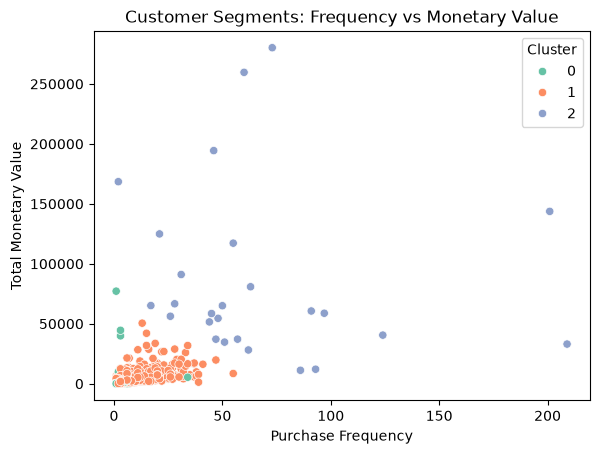

In [59]:
# Create a scatter plot of customer segments
sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="Set2"
)

plt.title("Customer Segments: Frequency vs Monetary Value")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Monetary Value")
plt.show()

### Interpretation

The scatter plot illustrates the relationship between purchase frequency and monetary value across the three customer clusters. Cluster 1 represents the largest group, with moderate purchase frequency and spending. Cluster 0 contains customers with relatively low purchase frequency and monetary value. Cluster 2 represents a small group of customers with very high purchase frequency and spending.

The chart also highlights the uneven distribution of customer spending, with a few customers contributing substantially higher monetary values.

### 10.2 Recency vs Monetary Value

This chart helps us understand whether customers who purchased recently also tend to spend more.

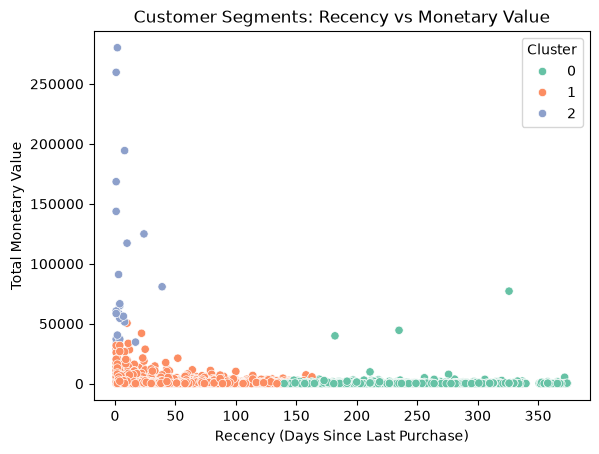

In [60]:
# Visualise recency against monetary value
sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="Set2"
)

plt.title("Customer Segments: Recency vs Monetary Value")
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Total Monetary Value")
plt.show()

### Interpretation

The scatter plot shows the relationship between customer recency and monetary value. Cluster 0 mainly contains less recently active customers with relatively low spending. Cluster 1 contains customers who have purchased more recently and show moderate spending. Cluster 2 represents a small group of recently active, high-value customers.

These patterns help identify customers who may need re-engagement and customers who should be prioritised for retention.

## 11. Business Insights and Recommendations



### Business Insights

1. **Cluster 0 – Less Active Customers:** Contains 1,082 customers (24.9%). These customers have high average recency and relatively low purchase frequency and spending.

2. **Cluster 1 – Regular Customers:** Contains 3,230 customers (74.5%). This is the largest segment, with relatively low recency and moderate purchase frequency and spending.

3. **Cluster 2 – High-Value Customers:** Contains 26 customers (0.6%). These customers have very low recency, high purchase frequency, and high monetary value.

### Business Recommendations

1. **For Cluster 0:** Introduce targeted discounts, reminder emails, and win-back campaigns to encourage customers to return.

2. **For Cluster 1:** Use loyalty programs, personalized recommendations, and repeat-purchase offers to increase customer engagement.

3. **For Cluster 2:** Provide VIP rewards, exclusive offers, and personalized services to retain these valuable customers.

4. **Overall:** Monitor customer purchasing behaviour regularly and update marketing strategies based on changing customer needs.

## 12. Conclusion



This project performed Customer Segmentation Analysis on an online retail dataset using Python, Pandas, Scikit-learn, Matplotlib, and Seaborn.

The dataset was cleaned by removing duplicate records, missing customer IDs, invalid dates, and transactions with non-positive quantities or unit prices.

RFM (Recency, Frequency, and Monetary) analysis was used to understand the purchasing behaviour of 4,338 unique customers. The K-Means clustering algorithm grouped these customers into three segments.

The analysis identified less active customers, regular customers, and a small group of high-value customers. Visualisations helped examine differences in customer purchasing frequency, recency, and monetary value.

Based on the findings, targeted marketing and customer retention strategies were recommended for each segment.

Overall, this project demonstrates how data analysis and machine learning techniques can help businesses understand customer behaviour and make informed marketing decisions.

## Exporting Customer Segmentation Results

In [61]:
# Save the RFM analysis and customer cluster assignments
rfm.to_csv("customer_segmentation_results.csv", index=False)

print("Customer segmentation results saved successfully.")

Customer segmentation results saved successfully.
